# North Atlantic Daily Ocean Temperature in 3-D: Identifying Marine Extremes at Depth with `MarEx-Detect`

This notebook turns a century (1950-2050) of daily potential temperature on seven levels between the surface and 1415 m
into a boolean record of marine heatwaves at every depth. The box covers the North Atlantic from 20°N to 60°N and 80°W
to 0° at 0.25°: the Gulf Stream and its extension, the subtropical gyre, the subpolar gyre south of Iceland, and the
Mediterranean outflow west of Gibraltar. The input is the EERIE `eerie-control-1950` run of IFS-FESOM2-SR, a coupled
control simulation under constant 1950 forcing.

The detection is the one used for the surface in the gridded and regional examples
([`../gridded/01_preprocess_extremes.ipynb`](../gridded/01_preprocess_extremes.ipynb)): `shifting_baseline` with the
day-of-year `seasonal_percentile` threshold (Hobday et al., 2016). marEx needs nothing extra for the depth axis. Any
dimension besides time and the horizontal ones is detected automatically and each level is treated independently, so
the call below is the surface call with one addition, a finer histogram bin width (Section 2). The rules are under
[Extra Dimensions](https://marex.readthedocs.io/en/latest/guide/dimensions_and_time.html#extra-dimensions).

A shifting (moving) baseline suits a long model run. Even without a forced trend this control run drifts: every level
of the box cools by 0.19-0.46 °C between its first and last 15 years. At 1415 m that is about twice the standard
deviation of the daily anomaly there, so against a fixed climatology the deep record would mostly measure the drift.
The shifting baseline measures each day against the preceding `window_years` (15) only, so its record starts in 1965,
15 years after the input.

Compute: the input is 36,890 days × 7 levels × 161 × 321 cells (53 GB in memory), about the size of the global gridded
example, so it runs on the same cluster: 256 single-threaded workers of 7.8 GB, started as 8 SLURM jobs of 32 on the
compute partition. The table at the end reports the wall time and memory of each stage.

## Setup

In [1]:
from getpass import getuser
from pathlib import Path

import cartopy.crs as ccrs
import dask
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import marEx
import marEx.helper as hpc

2026-10-23 14:27:17 - marEx - INFO - [PID:534137] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()  # Lustre scratch
thetao_store = (
    scratch_dir / "marEx_data" / "input" / "fesom_3d" / "fesom_thetao_northatlantic_daily_1950-2050.zarr"
)  # daily potential temperature (°C) on 7 levels, 20°N-60°N, 80°W-0°, 1950-01-01 to 2050-12-31
out_dir = scratch_dir / "marEx" / "examples" / "3d"

window_years = 15  # shifting-baseline length in years. The output starts this many years after the input
plot_window = slice("2030-01-01", "2035-12-31")  # x-range of the depth-time sections
points = {
    "Gulf Stream": (38.0, -65.0),
    "Subtropical gyre": (26.0, -50.0),
    "Subpolar gyre": (55.0, -30.0),
    "Mediterranean outflow": (36.0, -10.0),
}  # (lat, lon), all ocean down to 1415 m

# Workers run as short SLURM jobs on the compute partition: single-threaded, 32 per 256 GB node (7.8 GB each), 256 in all
n_workers, workers_per_node, runtime = 256, 32, 20  # workers, per 256 GB node, minutes per worker job

In [3]:
out_dir.mkdir(parents=True, exist_ok=True)

# the detect graph is about 25 MB at this scale, above dask's 10 MB warning default
dask.config.set({"distributed.admin.large-graph-warning-threshold": "64MB"})

# Each group of 32 workers is its own SLURM job on the compute partition. The walls cover the whole run: dask's P2P
# rechunk does not survive a worker leaving mid-shuffle, so workers are neither retired early nor replaced.
client = hpc.start_distributed_cluster(
    n_workers=n_workers,
    workers_per_node=workers_per_node,
    runtime=runtime,
    node_memory=256,
    scratch_dir=scratch_dir / "marEx" / "dask",
)
client.wait_for_workers(n_workers, timeout=1800)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-10-23 14:27:20 - marEx.helper.cluster - INFO - [PID:534137] - Starting distributed SLURM cluster - 256 workers on 8 nodes


2026-10-23 14:27:20 - marEx.helper.cluster - INFO - [PID:534137] - Configuration: 32 workers/node x 1 threads, 256GB memory/node, 20 min runtime


2026-10-23 14:27:20 - marEx.helper.dask_config - INFO - [PID:534137] - Configuring Dask for HPC environment


2026-10-23 14:27:20 - marEx.helper.dask_config - INFO - [PID:534137] - Dask temporary directory: /scratch/<u>/<user>/marEx/dask/tmpm2ma098l


2026-10-23 14:27:20 - marEx.helper.dask_config - INFO - [PID:534137] - Dask configuration completed


...

2026-10-23 14:27:21 - marEx.helper.cluster - INFO - [PID:534137] - Completed SLURM cluster creation in 1.22s


2026-10-23 14:27:21 - marEx.helper.cluster - INFO - [PID:534137] - Memory limit per worker: 7.81 GB


2026-10-23 14:27:21 - marEx.helper.cluster - INFO - [PID:534137] - Scaling cluster to 256 workers


Hostname: l40523
Forward Port: l40523:8889
Dashboard Link: localhost:8889/status
2026-10-23 14:27:21 - marEx.helper.cluster - INFO - [PID:534137] - Distributed cluster started successfully


2026-10-23 14:28:01 - marEx.helper.resources - INFO - [PID:534137] - Cluster: 256 workers, 256 threads, memory_limit per worker [7.8] GB (2001 GB total)


## 1. The Input and Its Drift

The store holds one `thetao` variable on `(time, lev, lat, lon)`, with land and seabed as NaN. It is read with the
chunking of the surface examples, a small time chunk with everything else whole (`{"time": 30}`), which is also the
store's on-disk layout. The level axis needs no entry in `dimensions`.

The figure shows the annual, area-weighted mean temperature of each level relative to its first 15 years, the span
that seeds the first shifting baseline. Every level cools. Near the surface the drift (about 0.46 °C over the century)
is a few times the year-to-year scatter of the level mean. At 1415 m it is smaller (0.19 °C) but about 30 times that
scatter: a slow, smooth trend that a fixed baseline would read as a century-long cold anomaly.

In [4]:
thetao = xr.open_zarr(thetao_store, chunks={"time": 30, "lev": -1, "lat": -1, "lon": -1}).thetao
thetao

<xarray.DataArray 'thetao' (time: 36890, lev: 7, lat: 161, lon: 321)> Size: 53GB
dask.array<open_dataset-thetao, shape=(36890, 7, 161, 321), dtype=float32, chunksize=(30, 7, 161, 321), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 1kB 20.0 20.25 20.5 20.75 ... 59.25 59.5 59.75 60.0
  * lev      (lev) float64 56B 2.5 12.5 97.5 195.0 600.0 950.0 1.415e+03
  * lon      (lon) float64 3kB -80.0 -79.75 -79.5 -79.25 ... -0.5 -0.25 0.0
  * time     (time) datetime64[ns] 295kB 1950-01-01 1950-01-02 ... 2050-12-31
Attributes:
    long_name:  Time-mean sea water potential temperature
    mask_note:  59 cells with isolated NaN days in the source set NaN for the...
    note:       source attribute said K; values are degC (min -2.1, max 33.5 ...
    units:      degC

Input: annual level means: 0.3 min, peak worker memory 140.3 GB of 2001 GB (largest worker 0.7 of 7.8 GB), client 0.7 GB, spilled 0.0 GB, restarts 0


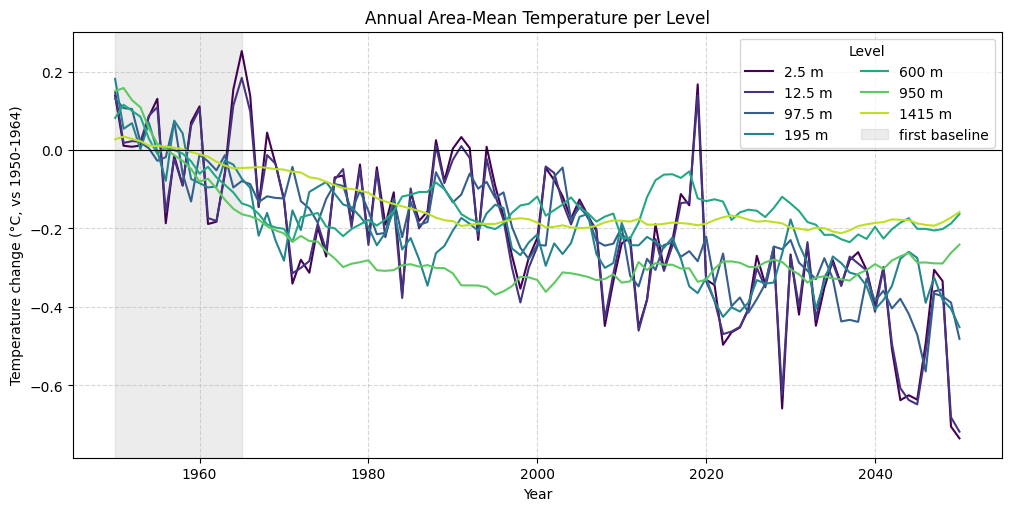

In [5]:
with monitor.stage("Input: annual level means"):
    weights = np.cos(np.deg2rad(thetao.lat))
    level_means = thetao.weighted(weights).mean(dim=["lat", "lon"]).resample(time="YE").mean().compute()

drift = level_means - level_means.isel(time=slice(0, window_years)).mean("time")

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
colours = plt.cm.viridis(np.linspace(0, 0.9, drift.sizes["lev"]))
for colour, lev in zip(colours, drift.lev.values):
    ax.plot(drift.time.dt.year, drift.sel(lev=lev), color=colour, label=f"{lev:g} m")
ax.axvspan(1950, 1950 + window_years, color="grey", alpha=0.15, label="first baseline")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature change (°C, vs 1950-1964)")
ax.set_title("Annual Area-Mean Temperature per Level")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(ncol=2, title="Level")
plt.show()

## 2. Shifting Baseline & Hobday Threshold in 3-D

The arguments are those of the surface examples. marEx logs the extra dimension it found, and every output that has a
spatial dimension gains `lev`: `mask` is `(lev, lat, lon)`, because the seabed rises above the deeper levels, and
`thresholds` is `(lev, lat, lon, dayofyear)`.

The one argument that depth does change is `precision`, the bin width of the approximate percentile. All levels
share one set of bins, and the default (3000 bins over the data's range, here 0.012 °C) is about an eighth of the anomaly
standard deviation at 1415 m (0.1 °C). Bins that coarse shift the deep threshold enough to raise the event frequency
there from 5 % to 5.7 %. A bin width of 0.004 °C, about 4 % of the quietest level's standard deviation, brings it to
5.2 % (the table in Section 5), with about 9000 bins instead of 3000.

In [6]:
with monitor.stage("Detect: shifting baseline + Hobday"):
    extremes_ds = marEx.preprocess_data(
        thetao,
        method_anomaly="shifting_baseline",  # anomaly from a backward-looking climatology of the previous `window_years`
        method_extreme="seasonal_percentile",  # day-of-year threshold (Hobday et al., 2016)
        threshold_percentile=95,
        window_years=window_years,
        smooth_days=21,  # smoothing applied to the climatology (days)
        window_days=11,  # samples from an 11-day window around each day of year enter its percentile
        precision=0.004,  # histogram bin width (°C), set from the quietest level: see above
        dimensions={"time": "time", "x": "lon", "y": "lat"},  # `lev` is found automatically
        dask_chunks={"time": 25},  # chunking of the output
    )
    extremes_ds.to_zarr(out_dir / "extremes_shifting_hobday_3d.zarr", mode="w")
extremes_ds

2026-10-23 14:28:24 - marEx.pipeline - INFO - [PID:534137] - Starting data preprocessing - Method: shifting_baseline -> seasonal_percentile


2026-10-23 14:28:24 - marEx.pipeline - INFO - [PID:534137] - Parameters: percentile=95%, method_percentile=approximate


2026-10-23 14:28:24 - marEx.anomaly.api - INFO - [PID:534137] - Computing anomalies - method: shifting_baseline


2026-10-23 14:28:24 - marEx.anomaly.api - INFO - [PID:534137] - Extra (non-horizontal) dimensions detected and carried through: ['lev']


2026-10-23 14:28:26 - marEx.anomaly.api - INFO - [PID:534137] - Starting Anomaly computation using shifting_baseline method


...

2026-10-23 14:36:25 - marEx.core.finalise - INFO - [PID:534137] - Starting Dataset persistence and optimisation


2026-10-23 14:36:25 - marEx.core.finalise - INFO - [PID:534137] - Completed Dataset persistence and optimisation in 0.09s


2026-10-23 14:36:53 - marEx.extremes.api - INFO - [PID:534137] - Extreme identification completed - <xarray.DataArray 'extreme_events' ()> Size: 8B
array(414562104) extreme events identified


Detect: shifting baseline + Hobday: 8.7 min, peak worker memory 1211.5 GB of 2001 GB (largest worker 5.5 of 7.8 GB), client 4.4 GB, spilled 101.2 GB, restarts 0


<xarray.Dataset> Size: 57GB
Dimensions:         (lat: 161, lev: 7, lon: 321, time: 31411, dayofyear: 366)
Coordinates:
  * lat             (lat) float64 1kB 20.0 20.25 20.5 20.75 ... 59.5 59.75 60.0
  * lev             (lev) float64 56B 2.5 12.5 97.5 195.0 600.0 950.0 1.415e+03
  * lon             (lon) float64 3kB -80.0 -79.75 -79.5 ... -0.5 -0.25 0.0
  * time            (time) datetime64[ns] 251kB 1965-01-01 ... 2050-12-31
  * dayofyear       (dayofyear) uint16 732B 1 2 3 4 5 6 ... 362 363 364 365 366
Data variables:
    dat_anomaly     (time, lev, lat, lon) float32 45GB dask.array<chunksize=(25, 7, 161, 321), meta=np.ndarray>
    mask            (lev, lat, lon) bool 362kB dask.array<chunksize=(7, 161, 321), meta=np.ndarray>
    extreme_events  (time, lev, lat, lon) bool 11GB dask.array<chunksize=(25, 7, 161, 321), meta=np.ndarray>
    thresholds      (lev, lat, lon, dayofyear) float32 530MB dask.array<chunksize=(7, 161, 321, 25), meta=np.ndarray>
Attributes: (12/13)
    method_anomaly:        shifting_baseline
    preprocessing_steps:   ['Rolling climatology using 15 years', 'Smoothed w...
    window_years:          15
    smooth_days:           21
    smooth_max_missing:    0.1
    method_extreme:        seasonal_percentile
    ...                    ...
    tail:                  upper
    window_days:           11
    window_spatial:        5
    method_percentile:     approximate
    precision:             0.004
    max_anomaly:           17.891708374023438

## 3. Maps per Level

`plotX` draws a 2-D field per panel, so a field with `lev` is plotted one level per panel with `col="lev"`. The
threshold is an anomaly, so it reads as how far above its recent baseline the water at that depth must be to count as
extreme.

Analysis: maps per level: 0.5 min, peak worker memory 257.6 GB of 2001 GB (largest worker 1.4 of 7.8 GB), client 4.6 GB, spilled 0.0 GB, restarts 0
2026-10-23 14:37:34 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 1.31s


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


...

2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:35 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


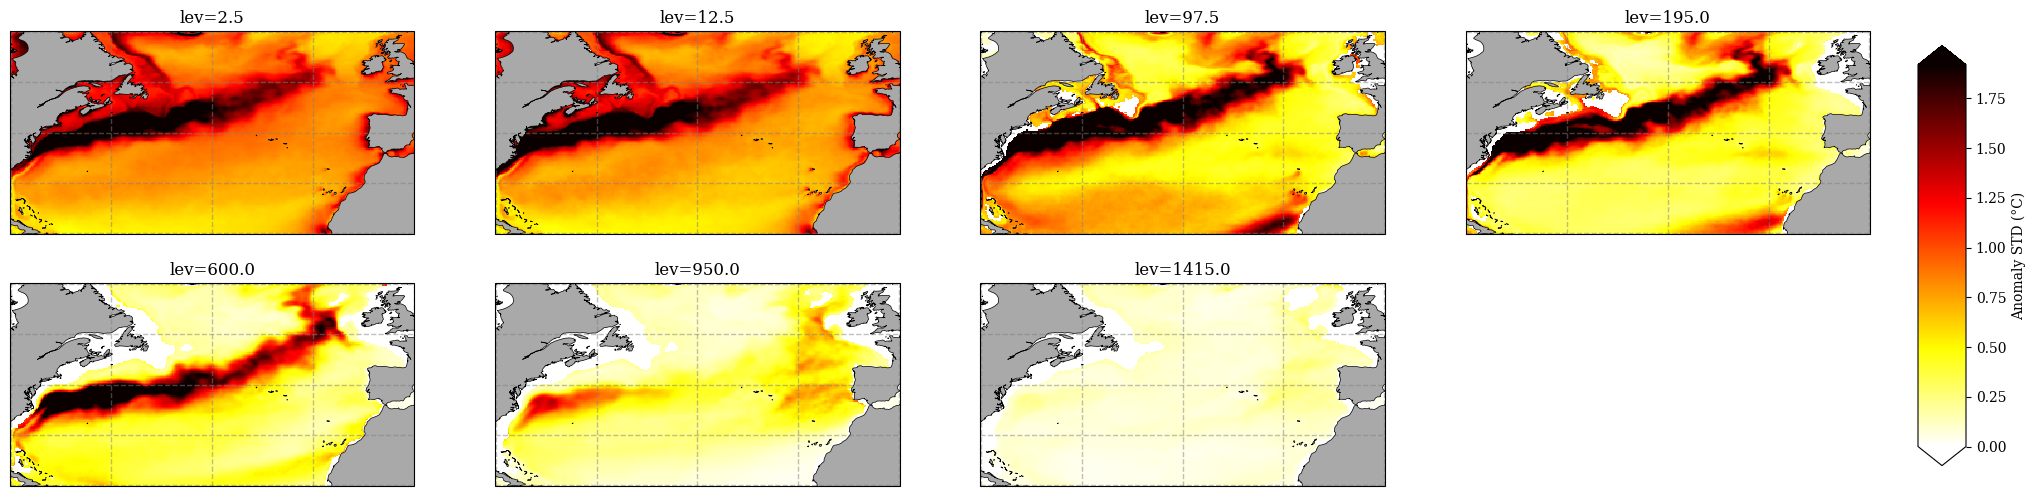

2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


...

2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:37 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


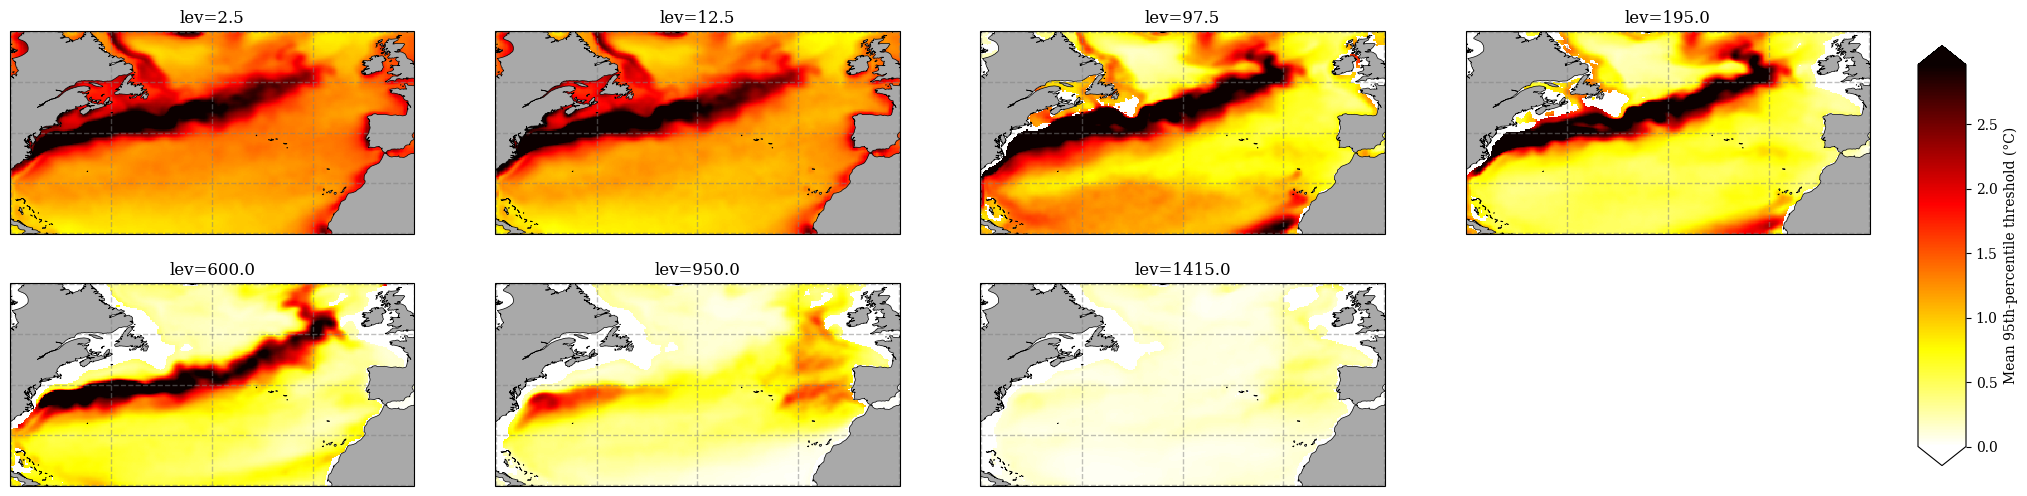

In [7]:
extremes_ds = xr.open_zarr(out_dir / "extremes_shifting_hobday_3d.zarr", chunks={})
plot_chunks = {"time": 75, "lev": 1, "lat": -1, "lon": -1}
anomaly = extremes_ds.dat_anomaly.chunk(plot_chunks)
events = extremes_ds.extreme_events.chunk(plot_chunks)

with monitor.stage("Analysis: maps per level"):
    level_maps = xr.Dataset(
        {
            "frequency": events.mean(dim="time"),
            "anomaly_std": anomaly.std(dim="time"),
            "threshold": extremes_ds.thresholds.mean(dim="dayofyear"),
        }
    ).compute()

map_kwargs = {"grid_labels": False, "show_colorbar": True, "projection": ccrs.PlateCarree()}
for name, units, cmap in [
    ("anomaly_std", "Anomaly STD (°C)", "hot_r"),
    ("threshold", "Mean 95th-percentile threshold (°C)", "hot_r"),
]:
    config = marEx.PlotConfig(var_units=units, cmap=cmap, cperc=[0, 96], **map_kwargs)
    fig, axes = level_maps[name].plotX.multi_plot(config, col="lev", col_wrap=4)
    plt.show()

2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


...

2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Starting Gridded plot rendering


2026-10-23 14:37:38 - marEx.plotX.gridded - INFO - [PID:534137] - Completed Gridded plot rendering in 0.02s


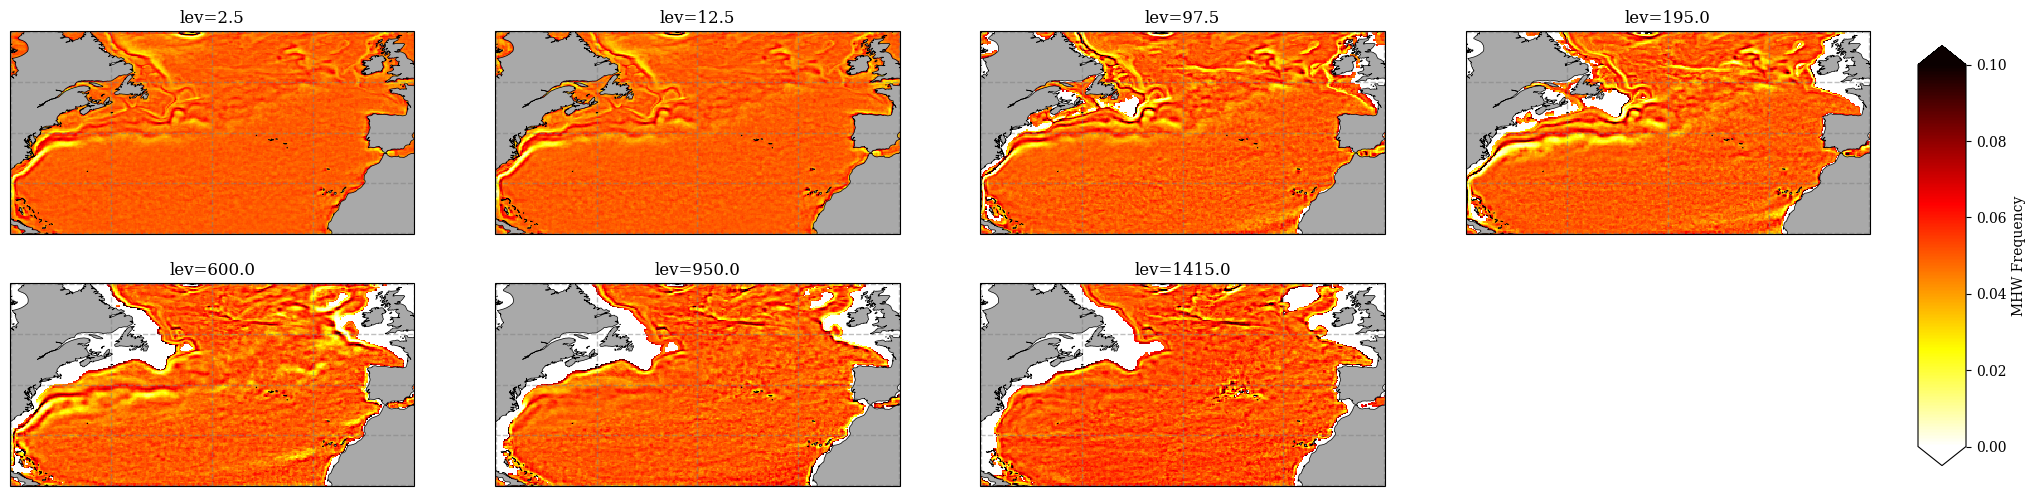

In [8]:
config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", clim=[0, 0.1], **map_kwargs)
fig, axes = level_maps.frequency.plotX.multi_plot(config, col="lev", col_wrap=4)
plt.show()

## 4. Depth-Time Sections

The anomaly at four points, level against time, with the days flagged as extreme outlined. The levels are unevenly
spaced, so each is drawn as one row of equal height. In the Gulf Stream, warm events reach from the surface to 600 m
together. Under the Mediterranean outflow, extremes at 950 m and 1415 m come and go with no surface counterpart.

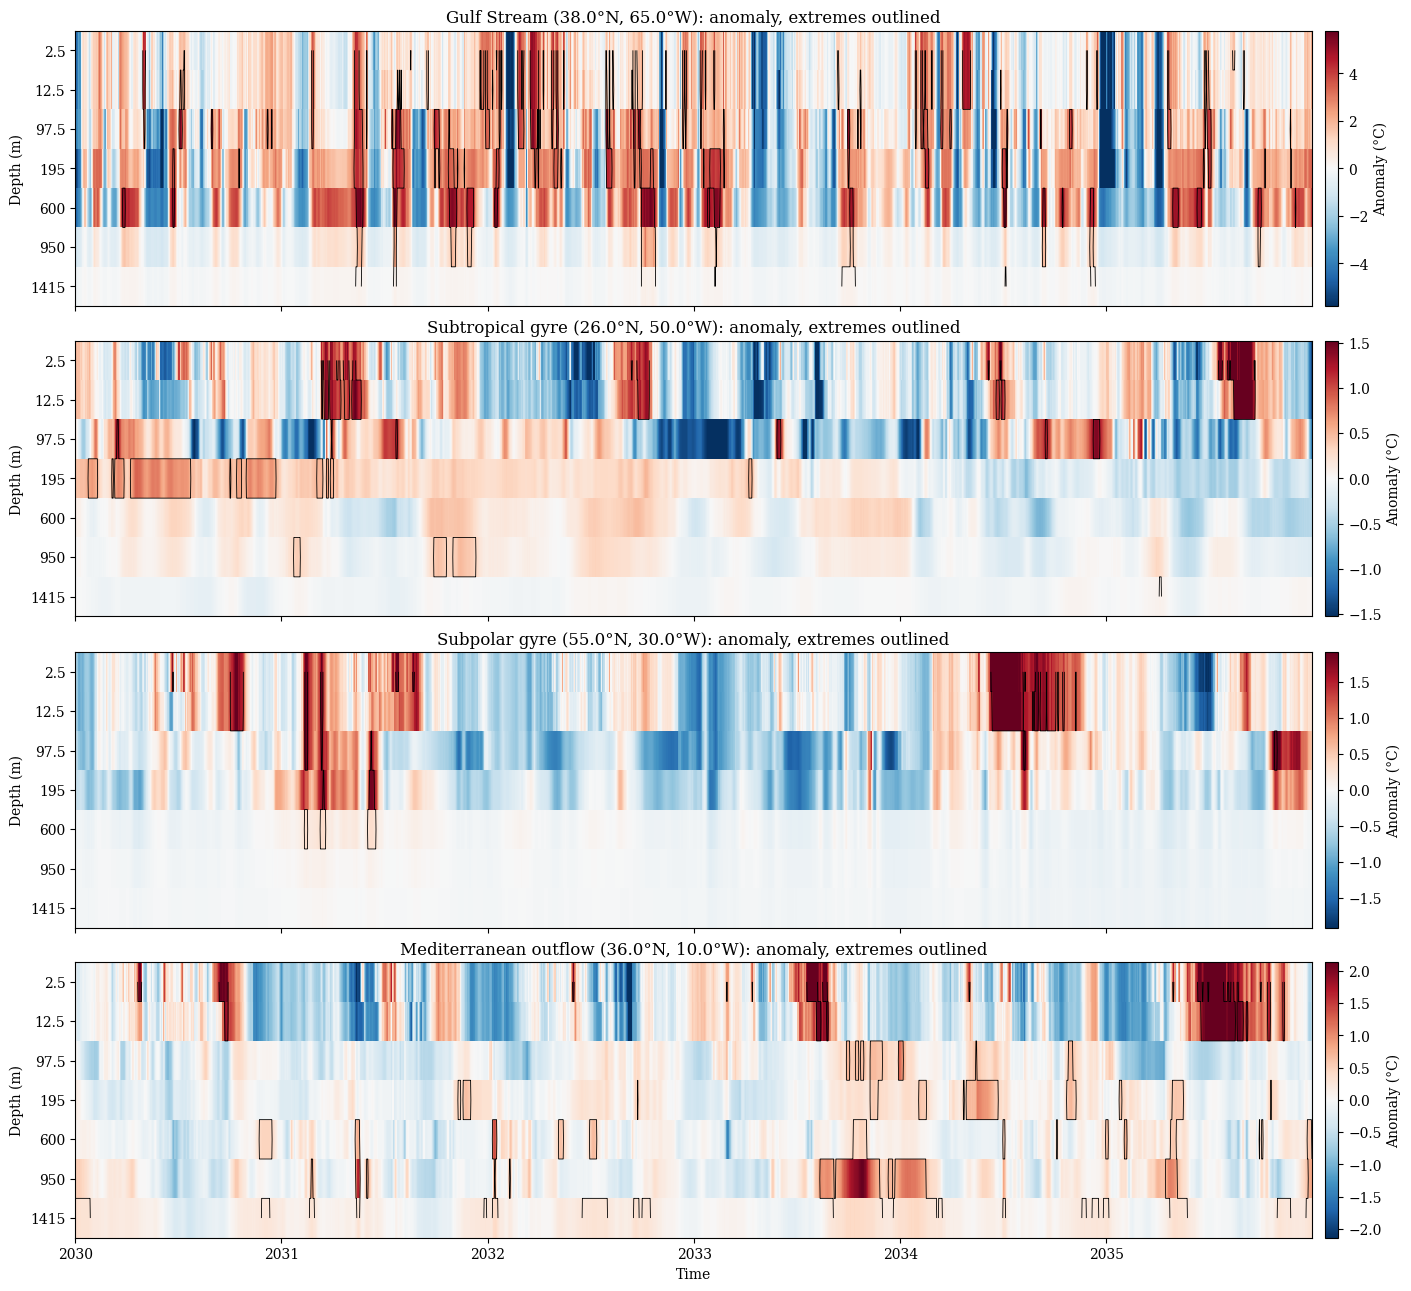

In [9]:
fig, axes = plt.subplots(len(points), 1, figsize=(14, 3.2 * len(points)), sharex=True, layout="constrained")
for ax, (name, (lat_pt, lon_pt)) in zip(axes, points.items()):
    at_point = {"lat": lat_pt, "lon": lon_pt}
    anomaly_pt = extremes_ds.dat_anomaly.sel(**at_point, method="nearest").sel(time=plot_window).compute()
    events_pt = extremes_ds.extreme_events.sel(**at_point, method="nearest").sel(time=plot_window).compute()
    limit = float(np.nanpercentile(np.abs(anomaly_pt), 99))
    rows = np.arange(anomaly_pt.sizes["lev"])
    mesh = ax.pcolormesh(anomaly_pt.time, rows, anomaly_pt.T, cmap="RdBu_r", vmin=-limit, vmax=limit, shading="nearest")
    ax.contour(events_pt.time, rows, events_pt.T.astype(int), levels=[0.5], colors="black", linewidths=0.6)
    ax.set_yticks(rows, [f"{lev:g}" for lev in anomaly_pt.lev.values])
    ax.invert_yaxis()
    ax.set_ylabel("Depth (m)")
    ax.set_title(f"{name} ({lat_pt}°N, {abs(lon_pt)}°W): anomaly, extremes outlined")
    fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", pad=0.01)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].set_xlabel("Time")
plt.show()

## 5. Vertical Structure

Area-weighted profiles over the ocean at each level. The left panel shows how variability and the threshold change with
depth. The right panel shows how often an extreme at one level coincides with one at the surface in the same column.
An extreme at depth with no surface extreme above it is invisible to sea-surface temperature. At 97.5 m only about a
quarter of extremes have one above them, and from 600 m down fewer than one in ten do.

Analysis: vertical profiles: 0.3 min, peak worker memory 242.4 GB of 2001 GB (largest worker 1.3 of 7.8 GB), client 4.7 GB, spilled 0.0 GB, restarts 0


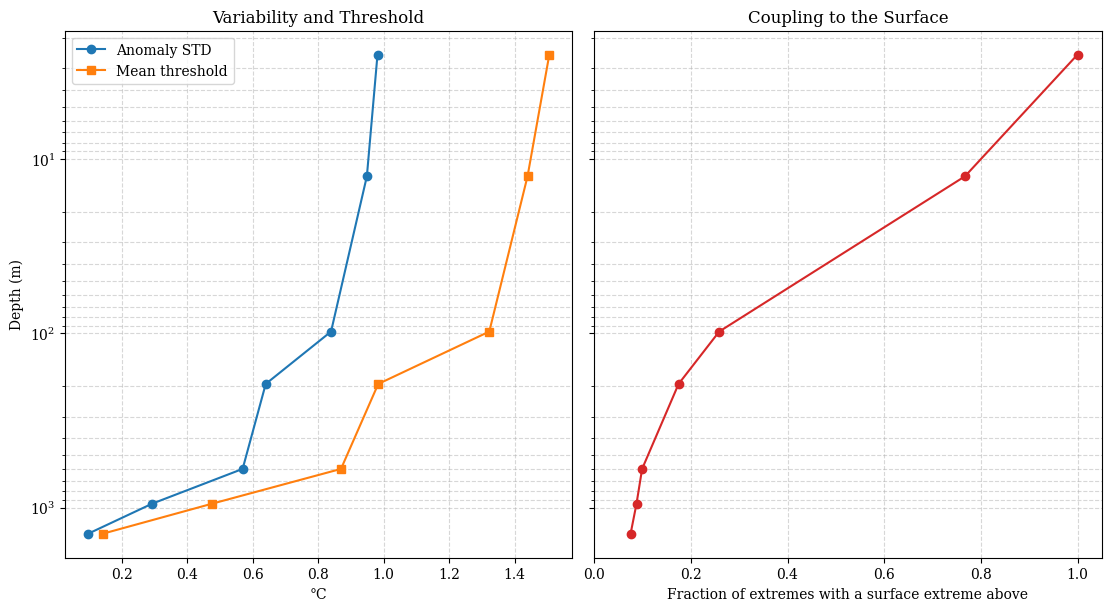

,frequency,anomaly_std,threshold,with_surface
lev,,,,
2.5,0.049,0.981,1.506,1.000
12.5,0.049,0.949,1.439,0.767
97.5,0.049,0.839,1.323,0.259
195.0,0.049,0.640,0.983,0.175
600.0,0.048,0.569,0.870,0.099
950.0,0.050,0.293,0.476,0.087
1415.0,0.052,0.097,0.141,0.075


In [10]:
with monitor.stage("Analysis: vertical profiles"):
    weights = np.cos(np.deg2rad(extremes_ds.lat))

    def area_mean(field):
        return field.where(extremes_ds.mask).weighted(weights).mean(dim=["lat", "lon"])

    surface_events = events.isel(lev=0, drop=True)
    joint = (events & surface_events).sum(dim=["time", "lat", "lon"])
    profiles = xr.Dataset(
        {
            "frequency": area_mean(level_maps.frequency),
            "anomaly_std": area_mean(level_maps.anomaly_std),
            "threshold": area_mean(level_maps.threshold),
            "with_surface": joint / events.sum(dim=["time", "lat", "lon"]),
        }
    ).compute()

fig, (ax_var, ax_cond) = plt.subplots(1, 2, figsize=(11, 6), sharey=True, layout="constrained")
ax_var.plot(profiles.anomaly_std, profiles.lev, marker="o", label="Anomaly STD")
ax_var.plot(profiles.threshold, profiles.lev, marker="s", label="Mean threshold")
ax_var.set_xlabel("°C")
ax_var.set_ylabel("Depth (m)")
ax_var.set_title("Variability and Threshold")
ax_var.legend()

ax_cond.plot(profiles.with_surface, profiles.lev, marker="o", color="tab:red")
ax_cond.set_xlim(0, 1.05)
ax_cond.set_xlabel("Fraction of extremes with a surface extreme above")
ax_cond.set_title("Coupling to the Surface")
for ax in (ax_var, ax_cond):
    ax.set_yscale("log")
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax_var.invert_yaxis()
plt.show()

profiles.to_dataframe().round(3)

## Wall Time and Memory

Peak memory summed over workers, the largest single worker, and the client (this kernel), per stage.

In [11]:
monitor.summary()

,wall (min),peak worker memory (GB),peak per worker (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,,
Input: annual level means,0.33,140.34,0.66,0.74,0.00,0
Detect: shifting baseline + Hobday,8.69,1211.52,5.50,4.38,101.21,0
Analysis: maps per level,0.47,257.58,1.36,4.57,0.00,0
Analysis: vertical profiles,0.30,242.39,1.32,4.73,0.00,0
total,9.78,1211.52,5.50,4.73,101.21,0


In [12]:
client.close()